## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the (X1,X2) points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ahlam Idris

**Date:** 10/08/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


Q1:

In [80]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [48]:
def createData(noise, N=50):
    np.random.seed(100)
    X1=np.array([np.random.normal(1,noise,N), np.random.normal(1,noise,N)])
    X2=np.array([np.random.normal(3,noise,N), np.random.normal(2,noise,N)])
    X3=np.array([np.random.normal(5,noise,N), np.random.normal(3,noise,N)])
    g = [pd.DataFrame({'x1':X[0],'x2':X[1],'group':i+1}) for i, X in enumerate([X1,X2,X3])]
    return pd.concat(g, axis=0)

In [49]:
noises= [0.125,0.25,0.5,1.0,2.0]
dfs= {n:createData(n) for n in noises}

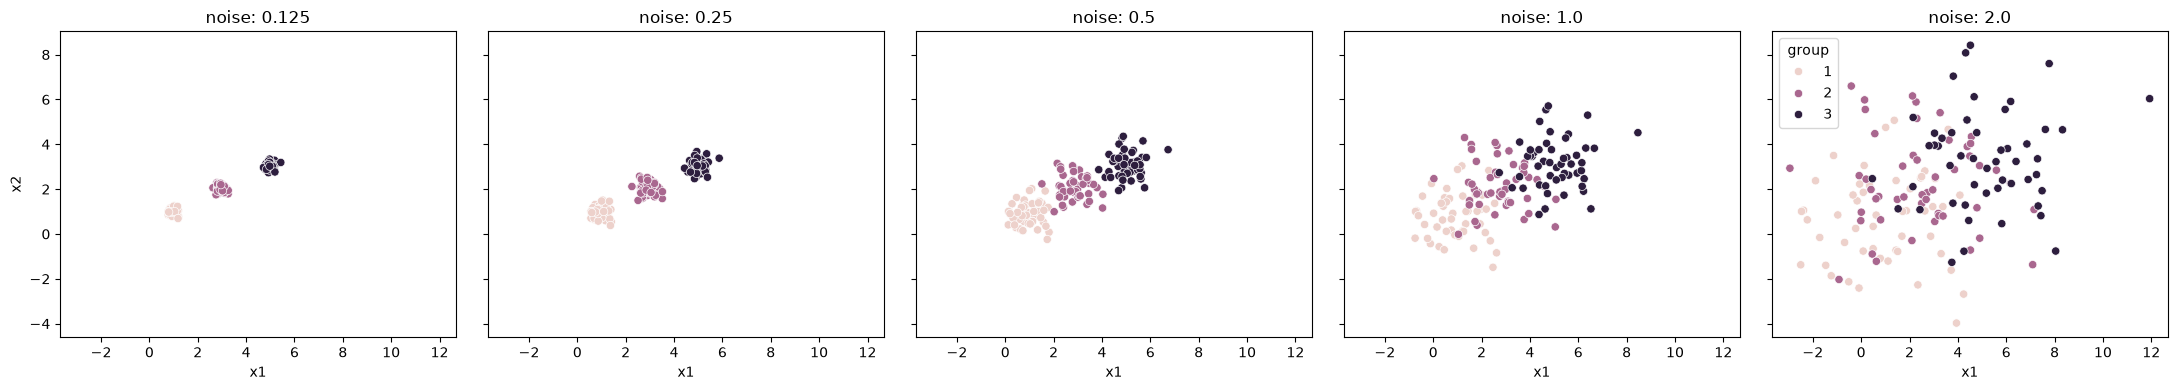

In [50]:
#Scatterplots for each dataset
fig, ax=plt.subplots(1,5, figsize=(22,4), sharex=True, sharey=True)
for a, n in zip(ax, noises):
    sns.scatterplot(data=dfs[n], x='x1', y='x2', hue='group', ax=a, legend=(n==2.0))
    a.set_title(f'noise: {n}')
plt.tight_layout(); plt.show()

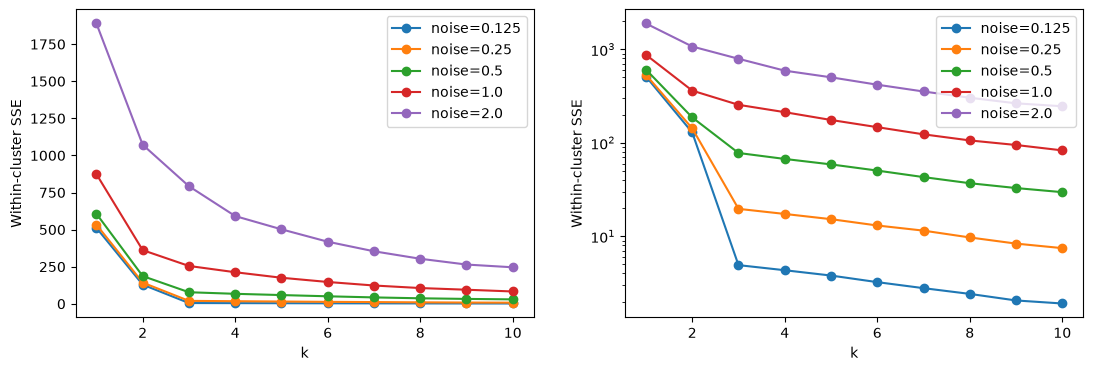

In [51]:
#Linear and log y-axis
ks=range(1,11)
sse= {n:[KMeans(k, n_init=10, random_state=0).fit(dfs[n][['x1', 'x2']]).inertia_ for k in ks] for n in noises}
fig,ax=plt.subplots(1,2, figsize=(13,4))
for n in noises:
    for a in ax:a.plot(ks,sse[n], marker='o', label=f'noise={n}')
ax[1].set_yscale('log')
for a in ax: a.set_xlabel('k'); a.set_ylabel('Within-cluster SSE'); a.legend()
plt.show()

2. As the noise goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

As the noise increases from 0.125 to 2.0, the cluters because harder to tell apart. When the noise was at 0.125 to 0.25 they are tight but separate however as it increases gradually, the edges begin to touch. In particular, the groups overlap a lot and the spread is roughly as big as the gap between centres so the groups blend into one cloud.


3. Describe how the level of noise affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a k. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

When there is low noise (0.125, 0.25), the scree plot has a sharp elbow at k=3 so that meeas that k=3 is easy to pick. As the noise increases, the elbow becomes weaker. At 1.0 it is blurry however, at 2.0 the curve is a smooth decline with no clear elbow so it makes it harder to confidently decide on k. Overall, SSE also gets larger as noise grows, so the low-noise curves look flat on a shared vertical axis.


4. Explain the intuition of the elbow, using this numerical simulation as an example

SSE always falls as k increases but the size of the drop is an important factor to keep in mind. Up to k=3, each new cluster splits real groups, so SSE drops a significant amount. After k=3, the new clusters only split noise, so SSE barely drops but the elbow is where the big drops stop. An example is when the noise 0.125, SSE goes 129 to 4.9 from k= 2 to 3, but only 4.9 to 4.3 from k=3 to 4.

Q2:

In [52]:
d= pd.read_csv('SIPRI Military Expenditure Database.csv')
d=d[d.Year== 2020].dropna().reset_index(drop=True) #148 rows

In [77]:
def mm(df,cols): return (df[cols]-df[cols].min())/(df[cols].max()-df[cols].min())

In [78]:
def scree(Z, title, kmax=10):
    s = [KMeans(k, n_init=10, random_state=0).fit(Z).inertia_ for k in range(1, kmax+1)]
    plt.plot(range(1, kmax+1), s, marker='o')
    plt.xlabel('k'); plt.ylabel('SSE'); plt.title(title); plt.show()

def analyze(cols, k, name):
    Z = mm(d, cols); scree(Z, name)
    d[name] = KMeans(k, n_init=10, random_state=0).fit_predict(Z)
    print(d[d.Country.str.contains('United States')][['Country', name]])
    for c, g in d.groupby(name): print(c, len(g), list(g.Country)[:40])
    return d.groupby(name)[cols].describe().T

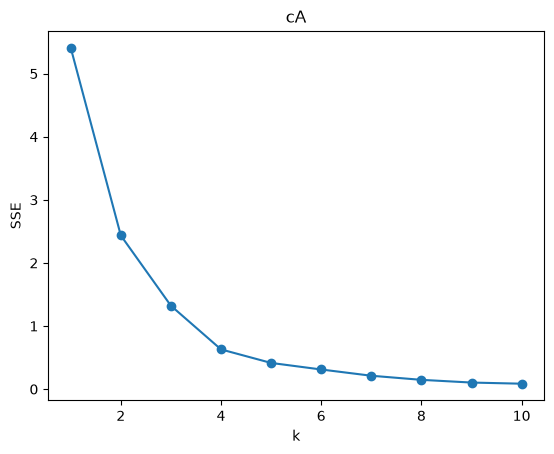

                      Country  cA
144  United States of America   2
0 21 ['Australia', 'Bahrain', 'Brunei', 'Canada', 'Denmark', 'Finland', 'France', 'Germany', 'Israel', 'Korea, South', 'Kuwait', 'Luxembourg', 'Netherlands', 'New Zealand', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore', 'Sweden', 'Switzerland', 'United Kingdom']
1 126 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Austria', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Cyprus', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Ethiopia']
2 1 ['United States of America']


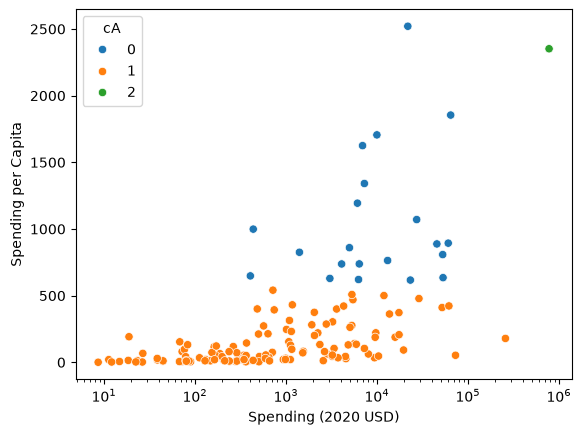

cA                                    0              1              2
Spending (2020 USD) count     21.000000     126.000000       1.000000
                    mean   19975.991473    5943.346303  778397.200000
                    std    21749.736747   24858.961064            NaN
                    min      405.790494       8.622460  778397.200000
                    25%     4980.428135     162.761743  778397.200000
                    50%     7269.880030     580.758315  778397.200000
                    75%    27300.894701    3225.333414  778397.200000
                    max    64558.400000  257973.429834  778397.200000
Spending per Capita count     21.000000     126.000000       1.000000
                    mean    1046.433509     122.034996    2351.631858
                    std      501.631845     140.041183            NaN
                    min      616.854430       0.580129    2351.631858
                    25%      737.690186      18.505805    2351.631858
                    50%      859.880548      58.809109    2351.631858
                    75%     1193.598730     188.249364    2351.631858
                    max     2520.398541     541.154778    2351.631858

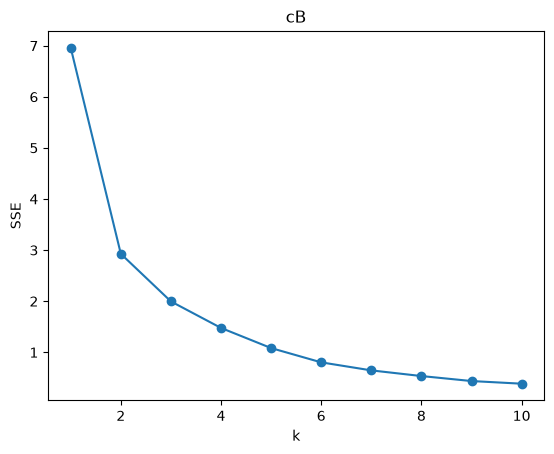

                      Country  cB
144  United States of America   0
0 39 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 10 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 99 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia', 'Eth

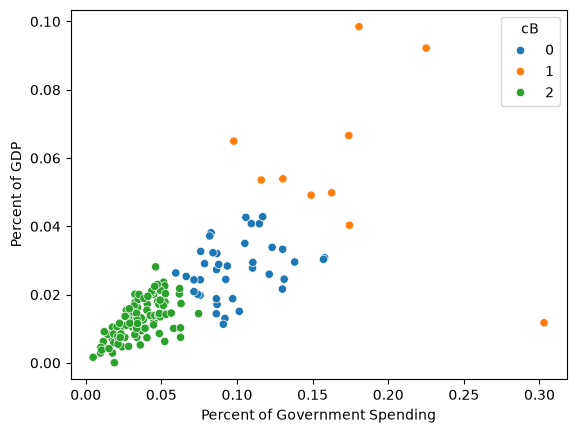

cB                                            0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                               50%     0.027781   0.053729   0.013191
                               75%     0.032461   0.066190   0.016752
                               max     0.042810   0.098470   0.028132

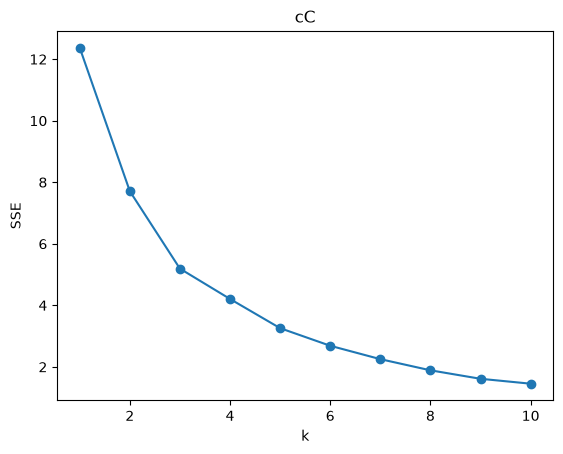

                      Country  cC
144  United States of America   1
0 86 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Bangladesh', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland']
1 6 ['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']
2 30 ['Algeria', 'Armenia', 'Azerbaijan', 'Bahrain', 'Belarus', 'Botswana', 'Brunei', 'Burkina Faso', 'Cambodia', 'Chad', 'Colombia', 'Congo, Republic', 'India', 'Iran', 'Iraq', 'Jordan', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Pakistan', 'Russia', 'Taiwan', 'Togo', 'Tunisia', 'Uganda'

cC                                                0              1  \
Spending (2020 USD)            count      86.000000       6.000000   
                               mean     4513.543790  147964.582042   
                               std     27841.230783  309635.189564   
                               min         8.622460    6095.708713   
                               25%        81.022976    7700.424616   
                               50%       288.061512   15897.570598   
                               75%      1138.618231   53872.942442   
                               max    257973.429834  778397.200000   
Spending per Capita            count      86.000000       6.000000   
                               mean       70.290644    1875.150751   
                               std        81.690590     489.800206   
                               min         0.580129    1193.598730   
                               25%        11.522275    1645.301864   
                               50%        34.845855    1780.059564   
                               75%        95.985387    2227.318999   
                               max       314.201312    2520.398541   
Percent of Government Spending count      86.000000       6.000000   
                               mean        0.043199       0.135351   
                               std         0.021512       0.055392   
                               min         0.004896       0.081976   
                               25%         0.028414       0.101034   
                               50%         0.040096       0.113271   
                               75%         0.053006       0.164503   
                               max         0.101501       0.225050   
Percent of GDP                 count      86.000000       6.000000   
                               mean        0.012481       0.062634   
                               std         0.005799       0.028275   
                               min         0.000054       0.029429   
                               25%         0.007811       0.041272   
                               50%         0.012532       0.059257   
                               75%         0.016783       0.085398   
                               max         0.026340       0.098470   

cC                                               2             3  
Spending (2020 USD)            count     30.000000     26.000000  
                               mean    9073.543709  15330.618681  
                               std    18135.032885  18923.469359  
                               min      163.926877    405.790494  
                               25%      522.737081   3176.345598  
                               50%     1663.090134   5857.060906  
                               75%     8646.648849  21818.934764  
                               max    72937.064048  60675.039625  
Spending per Capita            count     30.000000     26.000000  
                               mean     215.920971    612.677541  
                               std      261.610456    241.189507  
                               min       18.297119    362.467076  
                               25%       46.200403    413.682029  
                               50%      137.955585    579.004604  
                               75%      219.021206    738.120108  
                               max      998.966186   1341.058851  
Percent of Government Spending count     30.000000     26.000000  
                               mean       0.123701      0.033280  
                               std        0.044494      0.011771  
                               min        0.076005      0.011613  
                               25%        0.092832      0.026028  
                               50%        0.115883      0.032077  
                               75%        0.136403      0.044645  
                               max        0.303027      0.052209  
Percent of GDP

In [79]:
resA = analyze(colsA, 3, 'cA')
sns.scatterplot(data=d, x=colsA[0], y=colsA[1], hue='cA', palette='tab10')
plt.xscale('log'); plt.show()
display(resA)

resB = analyze(colsB, 3, 'cB')
sns.scatterplot(data=d, x=colsB[0], y=colsB[1], hue='cB', palette='tab10'); plt.show()
display(resB)

resC = analyze(colsC, 4, 'cC')
display(resC)

1. Is there any further cleaning of the variables required?

There isn't any further cleaning that is required because after filtering to 2020 and dropping the missing values, you have 148 countries and every column is numeric. The spending is very skewed and it has the US far above everyone else.


2. What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

The United States is in its own cluster with roughly $778 billion in spending and about $2,352 per capita. There are about 21 countries that have high spending per person and about 126 countries have low spending per person including countries like China, India, and Russia. The pattern that I found is that the clusters mostly follow country wealth and size. The scree plot bends at k=3 so I used 3 as k and when the elbow is weak I said that k=4.


3. How do your results compare to part 2?

The clusters demonstrate how heavy the military burden is, for example if it is low which are about 99 ountries, medium are about 39, and high are about 10 like Saudi Arabia, Algeria, and Oman. The US is now in the medium cluster so it is no longer an outlier with the other countries and the rich and poor countries share clusters. 


4. How do your results compare to the previous 2 parts?

This combines both parts 2 and 3 and a small group has both high spending and large burden which face countries like the US and Saudi Arabia. Rich countries have a high spending but low burden, while some countries have high burden but modest spending and the rest spend a little. The US is no longer an outlier alone.


5. Did the k-MC algorithm find any useful patterns for you in analyzing the spending?

A useful pattern is that k-means separated the US, rich low-burden countries, high-burden countries which is mostly the middle east, and a large low-spending majority. Using all four variables made it clearer and easy to understand. The US being an outlier and the unclear elbow limit tests how far you can trust the clusters.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** b20e493749e3e8d50a9e6998ad3febfad7e4f315
- **AI tool and model used:** Chat gpt - 5.6 Luna

### *Prompts used

1. Give me a concise numbered list on how to best answer this while making scatterplots from the datasets and assessing the clustering as well as cleaning the variables

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Clean data: Handle missing values, duplicates, incorrect data types, and irrelevant columns.
2. Select variables: Use x1, x2 for simulated data and relevant numerical variables for SIPRI.
3. Plot scatterplots: Color points by known groups or assigned clusters, keeping axes consistent.
4. Assess noise: Compare how increasing noise affects cluster separation and overlap.
5. Evaluate K-means: Plot SSE against k and use the elbow method to choose cluster numbers.
6. Scale SIPRI variables: Apply min–max scaling before clustering to prevent variables dominating due to scale.
7. Interpret clusters: Compare cluster sizes, variable summaries, and country memberships.
8. Conclude: Discuss clustering quality, limitations, and the effects of variable selection, scaling, and noise.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject |Accept| I accepted the suggestion regarding cleaning the data so that I could better understand and deal with the missing values and incorrect data types as well as the irrelevant columns.
| 2 | Accept / modify / reject | Accept| I accepted the suggestion regarding plotting the scatterplots and assigning colors to known groups or given clusters so that it is easy for anyone to follow and understand.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler

# =========================================================
# 1. GENERATE SIMULATED DATASETS
# =========================================================

def createData(noise, N=50):
    rng = np.random.RandomState(100)

    groups = [(1, 1, 'a'), (3, 2, 'b'), (5, 3, 'c')]
    frames = []

    for x_mean, y_mean, label in groups:
        frames.append(pd.DataFrame({
            'x1': rng.normal(x_mean, noise, N),
            'x2': rng.normal(y_mean, noise, N),
            'group': label
        }))

    return pd.concat(frames, ignore_index=True)


noises = [0.125, 0.25, 0.5, 1.0, 2.0]
dfs = {n: createData(n) for n in noises}

# Check missing values and data types
for noise, df in dfs.items():
    print(f"\nNoise = {noise}, shape = {df.shape}")
    print("Missing values:\n", df.isna().sum())
    print("Data types:\n", df.dtypes)


# =========================================================
# 2. SCATTERPLOTS FOR SIMULATED DATA
# =========================================================

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)

for ax, noise in zip(axes, noises):
    sns.scatterplot(
        data=dfs[noise],
        x='x1', y='x2',
        hue='group',
        hue_order=['a', 'b', 'c'],
        palette='Set1',
        ax=ax,
        legend=(noise == noises[-1])
    )
    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')

plt.tight_layout()
plt.show()


# =========================================================
# 3. K-MEANS SSE AND ELBOW PLOTS
# =========================================================

ks = range(1, 11)
sse = {}

for noise, df in dfs.items():
    X = df[['x1', 'x2']].dropna()

    sse[noise] = [
        KMeans(n_clusters=k, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for noise in noises:
    axes[0].plot(ks, sse[noise], marker='o', label=f'Noise={noise}')
    axes[1].plot(ks, sse[noise], marker='o', label=f'Noise={noise}')

for ax in axes:
    ax.set_xlabel('Number of clusters (k)')
    ax.set_ylabel('Within-cluster SSE')
    ax.legend()

axes[0].set_title('SSE: Linear scale')
axes[1].set_title('SSE: Log scale')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()


# =========================================================
# 4. LOAD AND CLEAN SIPRI DATA
# =========================================================

d = pd.read_csv('SIPRI Military Expenditure Database.csv')
d.columns = d.columns.str.strip()

print("\nOriginal columns:", d.columns.tolist())
print("\nOriginal data types:\n", d.dtypes)
print("\nOriginal missing values:\n", d.isna().sum())

# Convert Year to numeric and select 2020
d['Year'] = pd.to_numeric(d['Year'], errors='coerce')
d = d.loc[d['Year'] == 2020].copy()

# IMPORTANT: Replace these placeholders with your actual
# numerical SIPRI column names.
colsA = ['REPLACE_WITH_COLUMN_1', 'REPLACE_WITH_COLUMN_2']
colsB = ['REPLACE_WITH_COLUMN_1', 'REPLACE_WITH_COLUMN_2']
colsC = ['REPLACE_WITH_COLUMN_1', 'REPLACE_WITH_COLUMN_2']

all_cols = list(dict.fromkeys(colsA + colsB + colsC))

# Convert selected variables to numeric
for col in all_cols:
    d[col] = pd.to_numeric(d[col], errors='coerce')

# Remove rows missing required values and duplicate countries
d = d.dropna(subset=['Country'] + all_cols)
d = d.drop_duplicates(subset=['Country', 'Year'])
d = d.reset_index(drop=True)

print("\nCleaned SIPRI dataset shape:", d.shape)
print("\nRemaining missing values:\n", d[all_cols].isna().sum())


# =========================================================
# 5. ANALYZE SIPRI CLUSTERS
# =========================================================

def analyze(df, cols, k, name):
    # Select only relevant numerical variables
    X = df[cols].copy()

    # Remove constant variables
    X = X.loc[:, X.nunique() > 1]

    if X.shape[1] < 2:
        raise ValueError(
            f"{name}: at least two non-constant variables are required."
        )

    if len(df) <= k:
        raise ValueError(f"{name}: not enough rows for {k} clusters.")

    # Scale variables to the same range
    scaler = MinMaxScaler()
    Z = scaler.fit_transform(X)

    # Calculate SSE for elbow method
    ks = range(1, min(10, len(df) - 1) + 1)

    sse = [
        KMeans(n_clusters=i, n_init=10, random_state=0)
        .fit(Z).inertia_
        for i in ks
    ]

    plt.figure(figsize=(6, 4))
    plt.plot(list(ks), sse, marker='o')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Within-cluster SSE')
    plt.title(f'{name}: Elbow Plot')
    plt.tight_layout()
    plt.show()

    # Fit K-means using the selected number of clusters
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    labels = model.fit_predict(Z)

    result = df.copy()
    result[name] = labels

    # Scatterplot using the first two selected variables
    x_col, y_col = X.columns[:2]

    sns.scatterplot(
        data=result,
        x=x_col,
        y=y_col,
        hue=name,
        palette='tab10',
        s=60
    )

    plt.title(f'{name}: K-means Clusters')
    plt.tight_layout()
    plt.show()

    # Cluster sizes
    print(f"\n{name}: Cluster sizes")
    print(result[name].value_counts().sort_index())

    # Cluster summaries using original variable scales
    print(f"\n{name}: Cluster means")
    print(result.groupby(name)[list(X.columns)].mean().round(3))

    # Silhouette score evaluates cluster separation
    if 1 < k < len(df):
        print(
            f"{name}: Silhouette score =",
            round(silhouette_score(Z, labels), 3)
        )

    # Check United States membership
    print(f"\nUnited States membership for {name}:")
    print(
        result.loc[
            result['Country'].str.contains(
                'United States', case=False, na=False
            ),
            ['Country', name]
        ]
    )

    return result


# =========================================================
# 6. RUN ALL THREE SIPRI ANALYSES
# =========================================================

dA = analyze(d, colsA, 3, 'cA')
dB = analyze(d, colsB, 3, 'cB')
dC = analyze(d, colsC, 4, 'cC')

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI-assisted revision in phase 2 helped me improve my clustering assignment because it helped me strengthen my understanding of the k-means algorithm and how there are multiple different factors that impact the results. Through this assignment I’ve been able to explore the impact of noise on cluster separation, analyze the military spending data by grouping the countries based on different numeric variables and more. One limitation that I found was that AI could provide suggestions without fully accounting for the characteristics of the data or interpreting to understand if the results were actually meaningful. To verify my final solution, I re-ran all the codes from the beginning to ensure that they ran correctly with no errors, I rechecked the scatterplots and scree plots, as well as comparing the cluster results across the differing noise levels. By doing all of these checks, it helped me better grasp the concept of  scaling and variable selection. Overall, I found AI to be very useful for improving my code, analysis, and helping me understand the reasoning behind my results. A lingering question I have is about knowing how to select the ideal number of clusters and how to interpret the results accurately.